# Wheelchair-Friendly Route Planning with A* Search

**Problem:** standard map apps route by shortest distance or time, and ignore barriers like steep ramps and narrow footpaths that can make a route impossible for a wheelchair user.

**What this project does:**
1. Models a real area of Melbourne (Forest Hill, Nunawading and Blackburn) as a graph of **21 places and 30 path segments**, with steep and narrow segments marked
2. Plans routes with **A\*** and **Dijkstra** (uniform cost search) under three profiles: shortest, wheelchair-friendly and strict (never use barriers)
3. Checks that A\* always finds the optimal route, and measures how much search it saves compared with Dijkstra, on this map and on much larger generated maps
4. Shows what goes wrong when the heuristic overestimates (the bug in my first version)

The search code lives in [`planner.py`](planner.py), the map in [`forest_hill_map.py`](forest_hill_map.py), and the tests in [`tests/`](tests/).

## 1. Setup

In [1]:
import itertools
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forest_hill_map import DETOUR_FACTOR, LOCATIONS, RAW_SEGMENTS, build_segments, haversine_km
from planner import (PROFILES, Graph, _search, astar, describe, dijkstra, load_forest_hill,
                     straight_line_heuristic)

SHORTEST, WHEELCHAIR, BARRIER = "#2a78d6", "#1baf7a", "#eb6834"
INK, INK2, GRID, EDGE = "#0b0b0b", "#52514e", "#e4e3df", "#c9c8c2"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
})
IMG = "images"
G = load_forest_hill()
PAIRS = list(itertools.permutations(LOCATIONS, 2))
WAYPOINTS = {"Steep Ramp", "Narrow Pathway"}            # points on barrier segments, not real destinations
DEST_PAIRS = [(s, t) for s, t in PAIRS if s not in WAYPOINTS and t not in WAYPOINTS]
print(f"{len(G.edges)} map points, {len(build_segments())} segments")
print(f"{len(PAIRS)} start/goal pairs across all points; {len(DEST_PAIRS)} between the 19 real destinations")

21 map points, 30 segments
420 start/goal pairs across all points; 342 between the 19 real destinations


## 2. The map

Each place has real coordinates from Google Maps. Each segment has an estimated walking distance and a terrain type:
- **normal**
- **steep**: the steep ramp near Aqualink
- **narrow**: the narrow footpath near the SGNSS Gurdwara

**Data check:** a path can never be shorter than the straight line between its two ends, but 15 of the original distance estimates were. A* relies on this rule, so those segments are corrected. Estimates within 10% of the straight line are rounded up to it, and the rest are set to the straight line x 1.25, a typical urban detour factor.

In [2]:
raw = {(a, b): est for a, b, est, _ in RAW_SEGMENTS}
seg = pd.DataFrame(build_segments(), columns=["from", "to", "length_km", "terrain", "corrected"])
seg["original_estimate_km"] = [raw[(a, b)] for a, b in zip(seg["from"], seg["to"])]
seg["straight_line_km"] = [round(haversine_km(LOCATIONS[a], LOCATIONS[b]), 2) for a, b in zip(seg["from"], seg["to"])]
print(f"Corrected segments: {seg['corrected'].sum()} of {len(seg)}")
seg[seg["corrected"]][["from", "to", "original_estimate_km", "straight_line_km", "length_km"]].sort_values("original_estimate_km")

Corrected segments: 15 of 30


,from,to,original_estimate_km,straight_line_km,length_km
6,Mr Robertson Cafe,Nunawading Station,0.30,0.60,0.76
13,Hungry Jacks,Korean Restaurant,0.30,1.30,1.63
25,FF Collectibles,Nunawading Station,0.30,0.65,0.81
19,Ichikuro,Regis Blackburn,0.30,0.82,1.03
21,Steep Ramp,Aqualink,0.32,0.33,0.33
18,SGNSS Gurdwara,Blackburn Station,0.40,0.54,0.68
1,Narrow Pathway,SGNSS Gurdwara,0.55,0.56,0.57
15,Bob Saker,Aqualink,0.70,1.22,1.53
10,Korean Restaurant,Blackburn Station,1.20,1.35,1.69
16,Blackburn Primary School,SGNSS Gurdwara,1.30,1.66,2.08


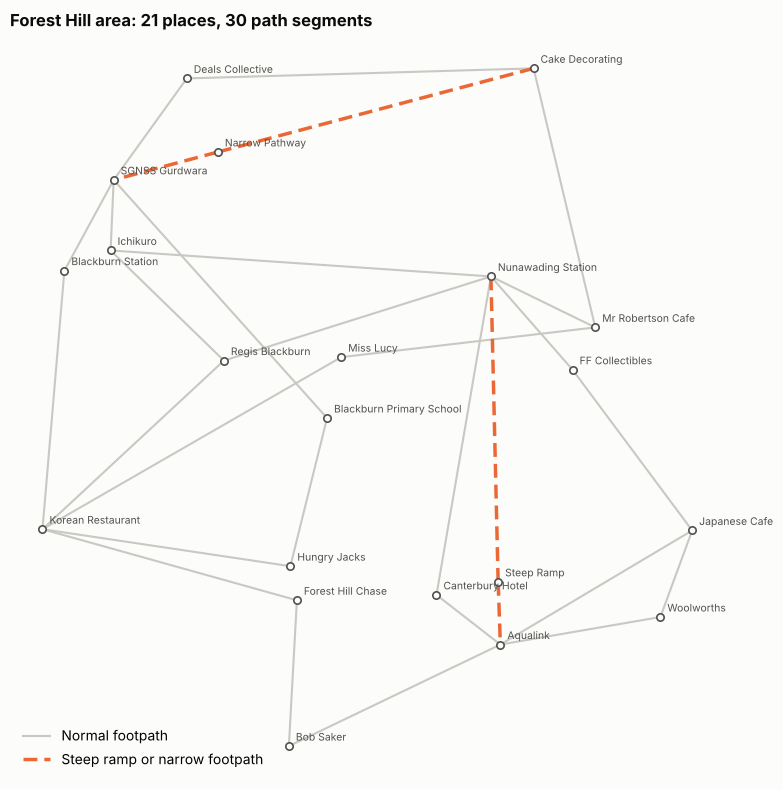

In [3]:
LAT0 = np.mean([lat for lat, _ in LOCATIONS.values()])

def xy(name):
    lat, lon = LOCATIONS[name]
    return lon, lat

def draw_base(ax, label_all=True):
    for a, b, _, terrain, _ in build_segments():
        (x1, y1), (x2, y2) = xy(a), xy(b)
        if terrain == "normal":
            ax.plot([x1, x2], [y1, y2], color=EDGE, linewidth=1.5, zorder=1)
        else:
            ax.plot([x1, x2], [y1, y2], color=BARRIER, linewidth=2.5, linestyle=(0, (4, 2)), zorder=2)
    xs, ys = zip(*(xy(n) for n in LOCATIONS))
    ax.scatter(xs, ys, s=28, color="#fcfcfb", edgecolor=INK2, linewidth=1.2, zorder=4)
    if label_all:
        for n in LOCATIONS:
            x, y = xy(n)
            ax.annotate(n, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=7.5, color=INK2, zorder=5)
    ax.set_aspect(1 / math.cos(math.radians(LAT0)))
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

fig, ax = plt.subplots(figsize=(10, 8))
draw_base(ax)
ax.plot([], [], color=EDGE, linewidth=1.5, label="Normal footpath")
ax.plot([], [], color=BARRIER, linewidth=2.5, linestyle=(0, (4, 2)), label="Steep ramp or narrow footpath")
ax.legend(loc="lower left", frameon=False)
ax.set_title("Forest Hill area: 21 places, 30 path segments", loc="left")
plt.tight_layout()
plt.savefig(f"{IMG}/map.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Route costs and the heuristic

**Route cost** = segment length x a terrain factor for the chosen profile:

| Profile | Normal | Steep ramp | Narrow footpath | Meaning |
|---|---|---|---|---|
| `shortest` | 1 | 1 | 1 | Plain distance, like a standard map app |
| `wheelchair` | 1 | 3 | 2 | Barriers count as 3x and 2x their length, so they're only used if the detour is long |
| `strict` | 1 | impassable | impassable | Never use a barrier |

The factors are adjustable assumptions, not measurements. A user could tune them to their own chair and ability.

**Heuristic:** the straight-line (great-circle) distance to the goal. It never overestimates, because:
- every segment is at least as long as the straight line between its ends (enforced above), and
- every terrain factor is at least 1.

That makes it **admissible and consistent**, so A* is guaranteed to return the cheapest route. The tests in `tests/test_planner.py` check this for every segment and every goal.

In [4]:
start, goal = "Blackburn Station", "Mr Robertson Cafe"
for profile in ("shortest", "wheelchair", "strict"):
    print(describe(G, astar(G, start, goal, profile), profile), "\n")

Route (shortest profile): Blackburn Station -> SGNSS Gurdwara -> Narrow Pathway -> Cake Decorating -> Mr Robertson Cafe
Distance: 4.35 km, about 52 min
  Blackburn Station -> SGNSS Gurdwara: 0.68 km
  SGNSS Gurdwara -> Narrow Pathway: 0.57 km  ! narrow footpath
  Narrow Pathway -> Cake Decorating: 1.70 km  ! narrow footpath
  Cake Decorating -> Mr Robertson Cafe: 1.40 km 

Route (wheelchair profile): Blackburn Station -> SGNSS Gurdwara -> Ichikuro -> Nunawading Station -> Mr Robertson Cafe
Distance: 4.42 km, about 53 min
  Blackburn Station -> SGNSS Gurdwara: 0.68 km
  SGNSS Gurdwara -> Ichikuro: 0.50 km
  Ichikuro -> Nunawading Station: 2.48 km
  Nunawading Station -> Mr Robertson Cafe: 0.76 km 

Route (strict profile): Blackburn Station -> SGNSS Gurdwara -> Ichikuro -> Nunawading Station -> Mr Robertson Cafe
Distance: 4.42 km, about 53 min
  Blackburn Station -> SGNSS Gurdwara: 0.68 km
  SGNSS Gurdwara -> Ichikuro: 0.50 km
  Ichikuro -> Nunawading Station: 2.48 km
  Nunawading Statio

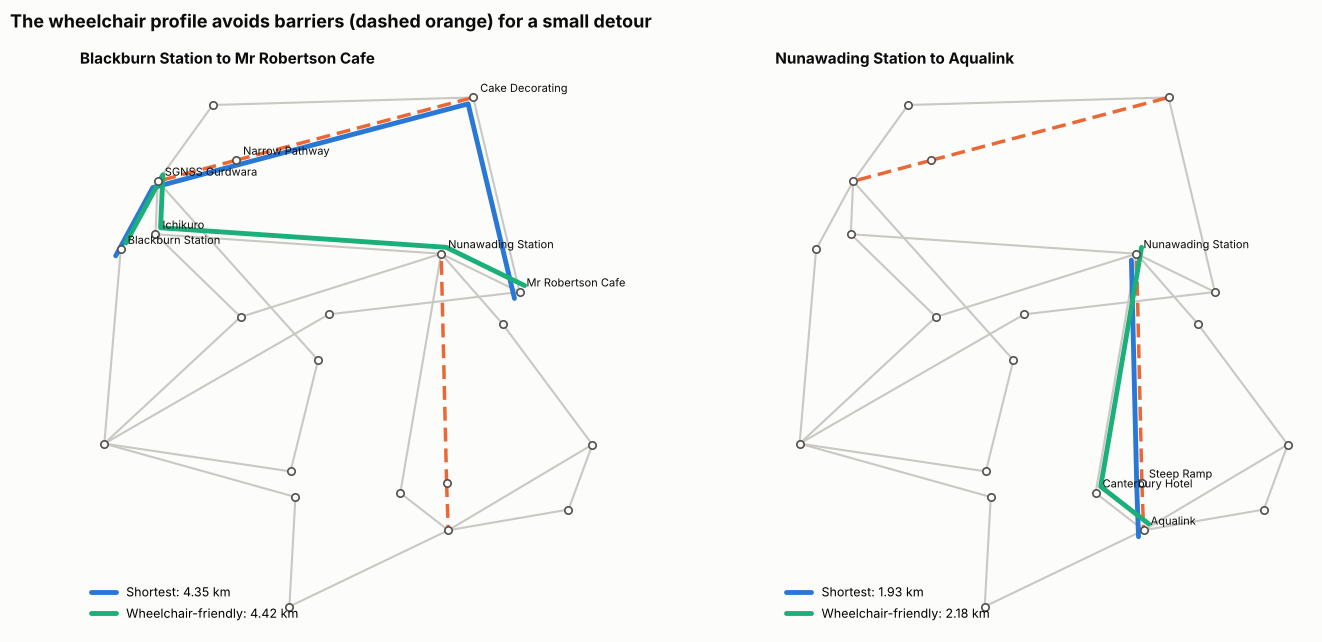

In [5]:
def draw_route(ax, path, colour, offset, label):
    pts = np.array([xy(n) for n in path])
    ax.plot(pts[:, 0] + offset, pts[:, 1] + offset, color=colour, linewidth=3.5, zorder=3, label=label,
            solid_capstyle="round")

examples = [("Blackburn Station", "Mr Robertson Cafe"),   # shortest route uses the narrow footpath
            ("Nunawading Station", "Aqualink")]           # shortest route uses the steep ramp

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (s, t) in zip(axes, examples):
    draw_base(ax, label_all=False)
    short, wc = astar(G, s, t, "shortest"), astar(G, s, t, "wheelchair")
    draw_route(ax, short.path, SHORTEST, -0.0004, f"Shortest: {short.distance:.2f} km")
    draw_route(ax, wc.path, WHEELCHAIR, 0.0004, f"Wheelchair-friendly: {wc.distance:.2f} km")
    for n in set(short.path) | set(wc.path):
        x, y = xy(n)
        ax.annotate(n, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK, zorder=5)
    ax.set_title(f"{s} to {t}", loc="left", fontsize=11)
    ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.suptitle("The wheelchair profile avoids barriers (dashed orange) for a small detour", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig(f"{IMG}/example_routes.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **Blackburn Station to Mr Robertson Cafe:** the shortest route (4.35 km) uses both narrow footpath segments. The wheelchair route goes via Ichikuro and Nunawading Station instead, which is only **70 m longer** (4.42 km).
- **Nunawading Station to Aqualink:** the shortest route (1.93 km) goes down the steep ramp. The wheelchair route goes via Canterbury Hotel, which is **250 m longer** (2.18 km).
- In both cases a standard "shortest route" app would send a wheelchair user over a barrier to save very little distance.

## 4. How often does the wheelchair profile change the route?

This covers every route between the 19 real destinations (342 start/goal pairs). The two barrier waypoints are excluded as start or end points.

In [6]:
rows = []
for s, t in DEST_PAIRS:
    short, wc, strict = (astar(G, s, t, p) for p in ("shortest", "wheelchair", "strict"))
    barriers = lambda r: sum(G.edges[a][b][1] != "normal" for a, b in zip(r.path, r.path[1:]))
    rows.append({"start": s, "goal": t, "short_km": short.distance, "wc_km": wc.distance,
                 "strict_km": strict.distance, "barriers_shortest": barriers(short),
                 "barriers_wheelchair": barriers(wc), "changed": short.path != wc.path})
routes = pd.DataFrame(rows)
uses_barrier = routes["barriers_shortest"] > 0
changed = routes[routes["changed"]]
print(f"Shortest routes that use a steep or narrow segment: {uses_barrier.sum()} of {len(routes)} ({uses_barrier.mean():.0%})")
print(f"Routes the wheelchair profile changes:              {len(changed)}")
print(f"Wheelchair routes still using a barrier:            {(routes['barriers_wheelchair'] > 0).sum()}")
extra = changed["wc_km"] - changed["short_km"]
print(f"Extra distance when rerouted:                       {extra.min():.2f} to {extra.max():.2f} km")
print(f"Strict profile reaches every destination:          {np.isfinite(routes['strict_km']).all()}")

Shortest routes that use a steep or narrow segment: 36 of 342 (11%)
Routes the wheelchair profile changes:              36
Wheelchair routes still using a barrier:            0
Extra distance when rerouted:                       0.07 to 0.25 km
Strict profile reaches every destination:          True


**Observations**
- **About 1 in 9 shortest routes (36 of 342) cross a steep ramp or narrow footpath.**
- **The wheelchair profile reroutes all 36**, at a cost of only 70 to 250 m extra, and no wheelchair route uses a barrier.
- **On this map, every destination is still reachable** with barriers fully blocked (the strict profile). On a real map with fewer alternatives, the strict profile would sometimes find no route, which is when the softer wheelchair profile matters.

## 5. A* vs Dijkstra on the Forest Hill map

This uses all 420 pairs of map points, including the waypoints, as a thorough correctness test. Both algorithms are guaranteed to find the cheapest route. The difference is **how much of the map they explore**. Dijkstra expands places in order of distance from the start, in every direction. A* uses the heuristic to focus on places that lead towards the goal.

In [7]:
rows = []
for s, t in PAIRS:
    a, d = astar(G, s, t, "wheelchair"), dijkstra(G, s, t, "wheelchair")
    rows.append({"start": s, "goal": t, "same_cost": math.isclose(a.cost, d.cost),
                 "astar_expanded": a.expanded, "dijkstra_expanded": d.expanded})
cmp = pd.DataFrame(rows)
print(f"A* found the optimal (same-cost) route in {cmp['same_cost'].sum()} of {len(cmp)} pairs")
print(f"Nodes expanded, mean: A* {cmp['astar_expanded'].mean():.1f}  vs  Dijkstra {cmp['dijkstra_expanded'].mean():.1f}")
print(f"A* expanded fewer nodes in {(cmp['astar_expanded'] < cmp['dijkstra_expanded']).mean():.0%} of pairs, "
      f"and never more: {(cmp['astar_expanded'] <= cmp['dijkstra_expanded']).all()}")

A* found the optimal (same-cost) route in 420 of 420 pairs
Nodes expanded, mean: A* 5.8  vs  Dijkstra 10.5
A* expanded fewer nodes in 93% of pairs, and never more: True


## 6. What went wrong in my first version

My original coursework version had three problems that together broke A*'s guarantee:
1. **Swapped coordinates.** Locations were stored as (longitude, latitude), but the distance formula read them as (latitude, longitude), so straight-line distances were wrong.
2. **Segment estimates shorter than the straight line** (the 15 segments corrected above).
3. **A terrain heuristic that added a 15 km penalty** at the steep ramp and narrow path places, on a map where most segments are about 1 km.

Problems 1 and 2 can make the heuristic overestimate, and problem 3 always does near the barriers. An overestimating (inadmissible) heuristic means A* can stop early with a worse route. This replays the original setup and checks every pair against the true optimum (Dijkstra on the same graph):

In [8]:
orig = Graph(coords=dict(LOCATIONS))
for a, b, est, terrain in RAW_SEGMENTS:
    orig.add(a, b, est, terrain)

def swapped_heuristic(goal, penalty=0.0):
    def h(n):
        d = haversine_km(LOCATIONS[n][::-1], LOCATIONS[goal][::-1])     # (lon, lat) read as (lat, lon)
        if penalty and ("Steep" in n or "Narrow" in n):
            d += penalty
        return d
    return h

results = {}
for name, make_h in [("Original: swapped coordinates", lambda t: swapped_heuristic(t)),
                     ("Original: swapped + 15 km terrain penalty", lambda t: swapped_heuristic(t, 15.0)),
                     ("Fixed data + straight-line heuristic", None)]:
    graph = orig if make_h else G
    worse = 0
    for s, t in PAIRS:
        opt = dijkstra(graph, s, t, "shortest").cost
        h = make_h(t) if make_h else straight_line_heuristic(G, t)
        got = astar(graph, s, t, "shortest", heuristic=h).cost
        worse += got > opt + 1e-9
    results[name] = worse
pd.Series(results, name="routes worse than optimal (of 420)").to_frame()

,routes worse than optimal (of 420)
Original: swapped coordinates,38
Original: swapped + 15 km terrain penalty,77
Fixed data + straight-line heuristic,0


**Observations**
- **With swapped coordinates alone, A* returned a worse-than-optimal route for 38 of 420 pairs.**
- **Adding the 15 km terrain penalty to the heuristic doubled that to 77.** Putting a cost into the heuristic doesn't make the route avoid it. It just breaks A*'s guarantee.
- **With the fixed data and a plain straight-line heuristic, A* matches the optimum on every pair.** Barrier avoidance now comes from the route cost (the profiles), which is where it belongs.
- **The lesson:** a heuristic must never overestimate. Anything you want the route to avoid goes into the edge costs, not the heuristic.

## 7. Does A* scale better? Larger generated maps

21 places is too small to show the real benefit. To test scalability, this generates street-grid style maps from 10x10 (100 places) to 120x120 (14,400 places):
- places on a jittered grid, 100 m apart, connected to their 4 neighbours
- each segment 0 to 30% longer than the straight line, so the heuristic stays admissible
- about 5% of segments marked as barriers

For each size, both algorithms plan 30 random long routes under the wheelchair profile.

In [9]:
def make_grid(n, seed=0):
    rng = random.Random(seed)
    coords = {(i, j): (i * 0.1 + rng.uniform(-0.03, 0.03), j * 0.1 + rng.uniform(-0.03, 0.03))
              for i in range(n) for j in range(n)}
    g = Graph(coords=coords)
    for (i, j) in coords:
        for di, dj in ((1, 0), (0, 1)):
            nb = (i + di, j + dj)
            if nb in coords:
                length = math.dist(coords[(i, j)], coords[nb]) * rng.uniform(1.0, 1.3)
                terrain = rng.choices(["normal", "steep", "narrow"], weights=[95, 2.5, 2.5])[0]
                g.add((i, j), nb, length, terrain)
    return g

rows = []
for n in (10, 20, 40, 80, 120):
    g = make_grid(n)
    rng = random.Random(n)
    nodes = list(g.coords)
    for _ in range(30):
        s, t = rng.sample(nodes, 2)
        h = lambda v, t=t: math.dist(g.coords[v], g.coords[t])
        t0 = time.perf_counter(); a = _search(g, s, t, "wheelchair", h); ta = time.perf_counter() - t0
        t0 = time.perf_counter(); d = _search(g, s, t, "wheelchair", lambda v: 0.0); td = time.perf_counter() - t0
        assert math.isclose(a.cost, d.cost)
        rows.append({"places": n * n, "astar_expanded": a.expanded, "dijkstra_expanded": d.expanded,
                     "astar_ms": ta * 1000, "dijkstra_ms": td * 1000})
scale = pd.DataFrame(rows).groupby("places").mean()
scale["expanded_ratio"] = scale["astar_expanded"] / scale["dijkstra_expanded"]
scale.round(2)

,astar_expanded,dijkstra_expanded,astar_ms,dijkstra_ms,expanded_ratio
places,,,,,
100,19.67,55.93,0.07,0.13,0.35
400,68.40,208.33,0.22,0.45,0.33
1600,320.83,911.77,1.06,2.33,0.35
6400,837.40,3023.83,2.35,6.52,0.28
14400,2784.47,9028.37,7.80,19.17,0.31


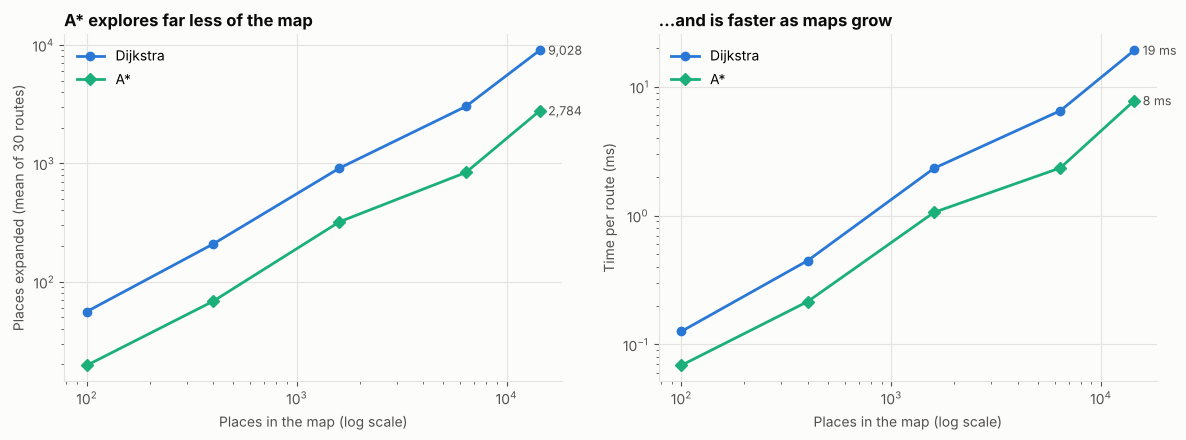

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (col_a, col_d, ylabel) in zip(axes, [("astar_expanded", "dijkstra_expanded", "Places expanded (mean of 30 routes)"),
                                              ("astar_ms", "dijkstra_ms", "Time per route (ms)")]):
    ax.plot(scale.index, scale[col_d], color=SHORTEST, marker="o", linewidth=2, label="Dijkstra")
    ax.plot(scale.index, scale[col_a], color=WHEELCHAIR, marker="D", linewidth=2, label="A*")
    for col, colour in [(col_d, SHORTEST), (col_a, WHEELCHAIR)]:
        v = scale[col].iloc[-1]
        ax.annotate(f"{v:,.0f}" if "expanded" in col else f"{v:.0f} ms", (scale.index[-1], v),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Places in the map (log scale)")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False)
axes[0].set_title("A* explores far less of the map", loc="left")
axes[1].set_title("...and is faster as maps grow", loc="left")
plt.tight_layout()
plt.savefig(f"{IMG}/scalability.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **At every map size, A* expands only about a third as many places as Dijkstra** (28 to 35%).
- **At 14,400 places, A* expands about 2,800 places per route against Dijkstra's 9,000,** and runs about 2.5 times faster.
- Both always return the same optimal cost (checked with an `assert` on every route).
- The saving comes from the heuristic pointing the search towards the goal. On a road network with millions of nodes, that difference decides whether routing is instant or sluggish.

## 8. Conclusions

| Question | Answer |
|---|---|
| Does a shortest-route planner put wheelchair users on barriers? | Yes: 11% of shortest routes on this map cross a steep ramp or narrow footpath |
| Can barriers be avoided cheaply? | Here, always, for 70 to 250 m extra |
| Does A* stay optimal? | Yes, on all 420 pairs, once the heuristic is admissible |
| Is A* worth it over Dijkstra? | Yes: same routes, about a third of the search, and the gap grows with map size |
| What did I learn? | Keep the heuristic admissible and put preferences (like avoiding barriers) in the cost function |

## 9. Limitations
- **Estimated data.** Segment lengths are estimates, and only two barriers are mapped. A real tool would use surveyed data on kerb ramps, slope gradients and footpath widths, e.g. from OpenStreetMap accessibility tags.
- **Terrain factors are assumptions.** The 3x and 2x weights are illustrative and should be set by, or with, wheelchair users.
- **Static conditions.** Temporary obstacles like roadworks or broken lifts would need edge costs to update over time. A* still works, but the map would need refreshing between searches.
- **Synthetic scalability test.** The large maps are generated grids, not real street networks, though real networks show the same pattern.

## References
[1] P. E. Hart, N. J. Nilsson and B. Raphael, "A formal basis for the heuristic determination of minimum cost paths," *IEEE Transactions on Systems Science and Cybernetics*, vol. 4, no. 2, pp. 100–107, 1968.

[2] S. Russell and P. Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed. Pearson, 2020.